In [1]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\samee\Desktop\Relax_Take_Home_Challenge

Files in this folder:
['.ipynb_checkpoints', 'Relax_Adopted_User_Analysis.ipynb', 'relax_challenge']


In [2]:
print(os.listdir("relax_challenge"))

['relax_data_science_challenge.pdf', 'takehome_users.csv', 'takehome_user_engagement.csv']


In [3]:
import pandas as pd

users = pd.read_csv("relax_challenge/takehome_users.csv", encoding="latin-1")
engagement = pd.read_csv("relax_challenge/takehome_user_engagement.csv")

print("USERS DATASET")
display(users.head())

print("USER ENGAGEMENT DATASET")
display(engagement.head())

USERS DATASET


,object_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,1.398139e+09,1,0,11,10803.0
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,1.396238e+09,0,0,1,316.0
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,1.363735e+09,0,0,94,1525.0
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,1.369210e+09,0,0,1,5151.0
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,1.358850e+09,0,0,193,5240.0


USER ENGAGEMENT DATASET


,time_stamp,user_id,visited
0,2014-04-22 03:53:30,1,1
1,2013-11-15 03:45:04,2,1
2,2013-11-29 03:45:04,2,1
3,2013-12-09 03:45:04,2,1
4,2013-12-25 03:45:04,2,1


In [4]:
print("USERS DATASET")
print("Rows and columns:", users.shape)
print("\nMissing values:")
print(users.isnull().sum())

print("\n" + "=" * 40)

print("USER ENGAGEMENT DATASET")
print("Rows and columns:", engagement.shape)
print("\nMissing values:")
print(engagement.isnull().sum())

USERS DATASET
Rows and columns: (12000, 10)

Missing values:
object_id                        0
creation_time                    0
name                             0
email                            0
creation_source                  0
last_session_creation_time    3177
opted_in_to_mailing_list         0
enabled_for_marketing_drip       0
org_id                           0
invited_by_user_id            5583
dtype: int64

USER ENGAGEMENT DATASET
Rows and columns: (207917, 3)

Missing values:
time_stamp    0
user_id       0
visited       0
dtype: int64


In [5]:
engagement["time_stamp"] = pd.to_datetime(engagement["time_stamp"])

daily_logins = engagement[["user_id", "time_stamp"]].copy()
daily_logins["login_date"] = daily_logins["time_stamp"].dt.normalize()
daily_logins = daily_logins[["user_id", "login_date"]].drop_duplicates()

daily_logins = daily_logins.sort_values(["user_id", "login_date"])

adopted_users = set()

for user_id, group in daily_logins.groupby("user_id"):
    dates = group["login_date"].sort_values().reset_index(drop=True)

    for i in range(len(dates)):
        days_in_window = (
            (dates <= dates.iloc[i] + pd.Timedelta(days=6))
            & (dates >= dates.iloc[i])
        ).sum()

        if days_in_window >= 3:
            adopted_users.add(user_id)
            break

users["adopted_user"] = users["object_id"].isin(adopted_users).astype(int)

print("Total users:", len(users))
print("Adopted users:", users["adopted_user"].sum())
print("Non-adopted users:", (users["adopted_user"] == 0).sum())
print("Adoption rate:", round(users["adopted_user"].mean() * 100, 2), "%")

Total users: 12000
Adopted users: 1602
Non-adopted users: 10398
Adoption rate: 13.35 %


In [6]:

adoption_by_source = (
    users.groupby("creation_source")["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_source.columns = [
    "creation_source",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_source["adoption_rate"] = (
    adoption_by_source["adoption_rate"] * 100
).round(2)

adoption_by_source = adoption_by_source.sort_values(
    "adoption_rate", ascending=False
)

display(adoption_by_source)

,creation_source,total_users,adopted_users,adoption_rate
4,SIGNUP_GOOGLE_AUTH,1385,232,16.75
0,GUEST_INVITE,2163,360,16.64
3,SIGNUP,2087,293,14.04
1,ORG_INVITE,4254,553,13.00
2,PERSONAL_PROJECTS,2111,164,7.77


In [7]:
adoption_by_mailing_list = (
    users.groupby("opted_in_to_mailing_list")["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_mailing_list.columns = [
    "opted_in_to_mailing_list",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_mailing_list["adoption_rate"] = (
    adoption_by_mailing_list["adoption_rate"] * 100
).round(2)

display(adoption_by_mailing_list)

,opted_in_to_mailing_list,total_users,adopted_users,adoption_rate
0,0,9006,1188,13.19
1,1,2994,414,13.83


In [8]:
adoption_by_marketing = (
    users.groupby("enabled_for_marketing_drip")["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_marketing.columns = [
    "enabled_for_marketing_drip",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_marketing["adoption_rate"] = (
    adoption_by_marketing["adoption_rate"] * 100
).round(2)

display(adoption_by_marketing)

,enabled_for_marketing_drip,total_users,adopted_users,adoption_rate
0,0,10208,1356,13.28
1,1,1792,246,13.73


In [9]:
users["was_invited"] = (
    users["invited_by_user_id"].notna().astype(int)
)

adoption_by_invitation = (
    users.groupby("was_invited")["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_invitation.columns = [
    "was_invited",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_invitation["adoption_rate"] = (
    adoption_by_invitation["adoption_rate"] * 100
).round(2)

display(adoption_by_invitation)

,was_invited,total_users,adopted_users,adoption_rate
0,0,5583,689,12.34
1,1,6417,913,14.23


In [10]:

org_sizes = users.groupby("org_id")["object_id"].count()

users["org_size"] = users["org_id"].map(org_sizes)

print("Organization size summary:")
display(users["org_size"].describe())

print("Number of unique organizations:", users["org_id"].nunique())

Organization size summary:


count    12000.000000
mean        55.108500
std         64.023959
min          2.000000
25%         21.000000
50%         29.000000
75%         55.000000
max        319.000000
Name: org_size, dtype: float64

Number of unique organizations: 417


In [11]:
users["org_size_group"] = pd.qcut(
    users["org_size"],
    q=3,
    labels=["Small", "Medium", "Large"],
    duplicates="drop"
)

adoption_by_org_size = (
    users.groupby("org_size_group", observed=True)["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_org_size.columns = [
    "org_size_group",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_org_size["adoption_rate"] = (
    adoption_by_org_size["adoption_rate"] * 100
).round(2)

display(adoption_by_org_size)

,org_size_group,total_users,adopted_users,adoption_rate
0,Small,4071,651,15.99
1,Medium,4014,576,14.35
2,Large,3915,375,9.58


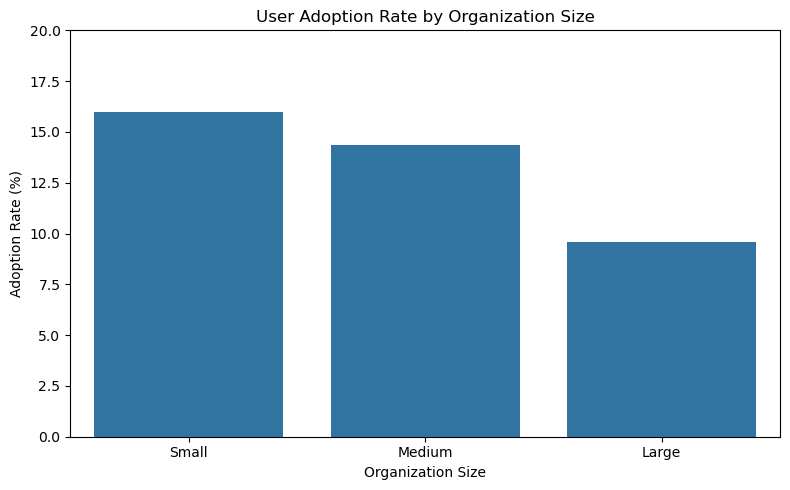

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=adoption_by_org_size,
    x="org_size_group",
    y="adoption_rate"
)

plt.title("User Adoption Rate by Organization Size")
plt.xlabel("Organization Size")
plt.ylabel("Adoption Rate (%)")
plt.ylim(0, 20)

plt.tight_layout()
plt.show()

In [13]:
users["creation_time"] = pd.to_datetime(users["creation_time"])

users["signup_weekday"] = users["creation_time"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

adoption_by_weekday = (
    users.groupby("signup_weekday")["adopted_user"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

adoption_by_weekday.columns = [
    "signup_weekday",
    "total_users",
    "adopted_users",
    "adoption_rate"
]

adoption_by_weekday["adoption_rate"] = (
    adoption_by_weekday["adoption_rate"] * 100
).round(2)

adoption_by_weekday["signup_weekday"] = pd.Categorical(
    adoption_by_weekday["signup_weekday"],
    categories=weekday_order,
    ordered=True
)

adoption_by_weekday = adoption_by_weekday.sort_values(
    "signup_weekday"
)

display(adoption_by_weekday)

,signup_weekday,total_users,adopted_users,adoption_rate
1,Monday,1712,218,12.73
5,Tuesday,1656,225,13.59
6,Wednesday,1689,235,13.91
4,Thursday,1803,238,13.20
0,Friday,1822,232,12.73
2,Saturday,1661,233,14.03
3,Sunday,1657,221,13.34


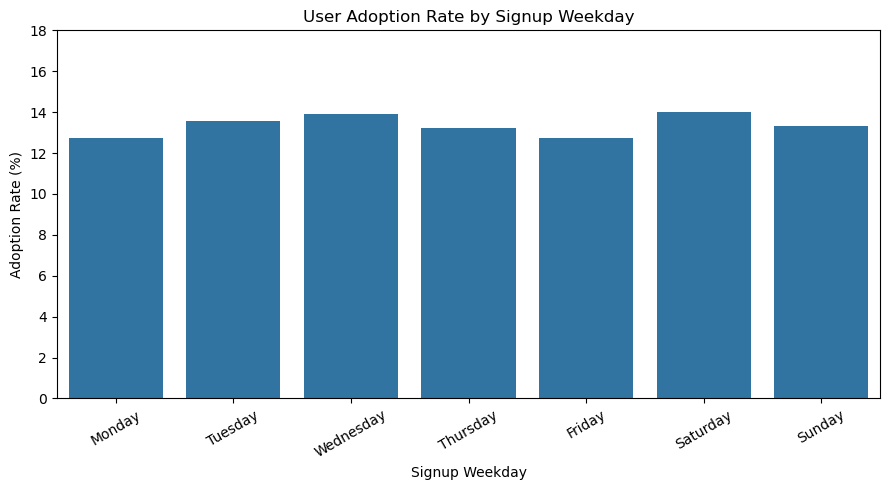

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=adoption_by_weekday,
    x="signup_weekday",
    y="adoption_rate"
)

plt.title("User Adoption Rate by Signup Weekday")
plt.xlabel("Signup Weekday")
plt.ylabel("Adoption Rate (%)")
plt.ylim(0, 18)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [15]:
feature_columns = [
    "creation_source",
    "opted_in_to_mailing_list",
    "enabled_for_marketing_drip",
    "org_size",
    "was_invited",
    "signup_weekday"
]

X = users[feature_columns].copy()
y = users["adopted_user"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFirst five rows of features:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (12000, 6)
Target dataset shape: (12000,)

First five rows of features:


,creation_source,opted_in_to_mailing_list,enabled_for_marketing_drip,org_size,was_invited,signup_weekday
0,GUEST_INVITE,1,0,75,1,Tuesday
1,ORG_INVITE,0,0,233,1,Friday
2,ORG_INVITE,0,0,32,1,Tuesday
3,GUEST_INVITE,0,0,233,1,Tuesday
4,GUEST_INVITE,0,0,16,1,Thursday



Target distribution:
adopted_user
0    10398
1     1602
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nAdoption rate in training set:", round(y_train.mean() * 100, 2), "%")
print("Adoption rate in testing set:", round(y_test.mean() * 100, 2), "%")

Training features: (9600, 6)
Testing features: (2400, 6)

Adoption rate in training set: 13.35 %
Adoption rate in testing set: 13.33 %


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

categorical_features = [
    "creation_source",
    "signup_weekday"
]

numerical_features = [
    "opted_in_to_mailing_list",
    "enabled_for_marketing_drip",
    "org_size",
    "was_invited"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        )
    ]
)

print("Preprocessing setup completed successfully.")

Preprocessing setup completed successfully.


In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict adoption for the test set
y_pred = logistic_model.predict(X_test)

# Predict adoption probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("MODEL EVALUATION RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy: 0.4471
Precision: 0.1609
Recall: 0.7469
F1-score: 0.2648
ROC-AUC: 0.6118

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.40      0.56      2080
           1       0.16      0.75      0.26       320

    accuracy                           0.45      2400
   macro avg       0.54      0.57      0.41      2400
weighted avg       0.81      0.45      0.52      2400

Confusion Matrix:
[[ 834 1246]
 [  81  239]]


In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
# Predict adoption using Random Forest
rf_pred = random_forest_model.predict(X_test)

# Predict probabilities for adopted users
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("RANDOM FOREST EVALUATION RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST EVALUATION RESULTS
-----------------------------------
Accuracy: 0.7229
Precision: 0.1338
Recall: 0.1969
F1-score: 0.1593
ROC-AUC: 0.5089

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.80      0.83      2080
           1       0.13      0.20      0.16       320

    accuracy                           0.72      2400
   macro avg       0.50      0.50      0.50      2400
weighted avg       0.77      0.72      0.74      2400

Confusion Matrix:
[[1672  408]
 [ 257   63]]


In [22]:
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create a feature importance table
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance", ascending=False
)

display(feature_importance.head(10))

,feature,importance
14,numerical__org_size,0.790896
12,numerical__opted_in_to_mailing_list,0.037455
13,numerical__enabled_for_marketing_drip,0.031351
2,categorical__creation_source_PERSONAL_PROJECTS,0.017519
5,categorical__signup_weekday_Friday,0.014181
7,categorical__signup_weekday_Saturday,0.013172
10,categorical__signup_weekday_Tuesday,0.013101
8,categorical__signup_weekday_Sunday,0.012231
6,categorical__signup_weekday_Monday,0.012076
9,categorical__signup_weekday_Thursday,0.011983


In [23]:
feature_columns_without_org_size = [
    "creation_source",
    "opted_in_to_mailing_list",
    "enabled_for_marketing_drip",
    "was_invited",
    "signup_weekday"
]

X_without_org_size = users[feature_columns_without_org_size].copy()

X_train_small, X_test_small, y_train_small, y_test_small = (
    train_test_split(
        X_without_org_size,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Training set:", X_train_small.shape)
print("Testing set:", X_test_small.shape)
print("Data prepared without organization size.")

Training set: (9600, 5)
Testing set: (2400, 5)
Data prepared without organization size.


In [24]:
# Create a preprocessing pipeline without organization size
preprocessor_small = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["creation_source", "signup_weekday"]
        ),
        (
            "numerical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            [
                "opted_in_to_mailing_list",
                "enabled_for_marketing_drip",
                "was_invited"
            ]
        )
    ]
)

# Build the Logistic Regression pipeline
logistic_model_small = Pipeline(steps=[
    ("preprocessor", preprocessor_small),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model_small.fit(X_train_small, y_train_small)

print("Logistic Regression without organization size trained!")

Logistic Regression without organization size trained!


In [25]:
# Predict adoption
y_pred_small = logistic_model_small.predict(X_test_small)

# Predict adoption probabilities
y_prob_small = logistic_model_small.predict_proba(X_test_small)[:, 1]

# Display evaluation metrics
print("LOGISTIC REGRESSION — WITHOUT ORGANIZATION SIZE")
print("-" * 50)

print("Accuracy:", round(accuracy_score(y_test_small, y_pred_small), 4))
print("Precision:", round(precision_score(y_test_small, y_pred_small, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_small, y_pred_small, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test_small, y_pred_small, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_small, y_prob_small), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_small, y_pred_small))

LOGISTIC REGRESSION — WITHOUT ORGANIZATION SIZE
--------------------------------------------------
Accuracy: 0.4133
Precision: 0.1477
Recall: 0.7125
F1-score: 0.2446
ROC-AUC: 0.5759

Confusion Matrix:
[[ 764 1316]
 [  92  228]]


In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Use probabilities from the original Logistic Regression model
threshold_results = []

for threshold in [0.3, 0.5, 0.7]:
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

for column in ["precision", "recall", "f1_score"]:
    threshold_comparison[column] = (
        threshold_comparison[column].round(3)
    )

display(threshold_comparison)

,threshold,precision,recall,f1_score
0,0.3,0.138,0.975,0.242
1,0.5,0.161,0.747,0.265
2,0.7,0.000,0.000,0.000


In [27]:
from sklearn.dummy import DummyClassifier

# Create a simple baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline
baseline_model.fit(X_train, y_train)

# Make predictions on the test set
baseline_pred = baseline_model.predict(X_test)

print("BASELINE MODEL")
print("-" * 30)
print("Accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Precision:", round(
    precision_score(y_test, baseline_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, baseline_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, baseline_pred, zero_division=0), 4
))

BASELINE MODEL
------------------------------
Accuracy: 0.8667
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [28]:
print("Total users:", len(users))
print("Adopted users:", int(users["adopted_user"].sum()))
print("Non-adopted users:", int((users["adopted_user"] == 0).sum()))
print("Adoption rate:", round(users["adopted_user"].mean() * 100, 2), "%")

print("\nDuplicate user IDs:", users["object_id"].duplicated().sum())
print("Duplicate daily login records:", daily_logins.duplicated().sum())

Total users: 12000
Adopted users: 1602
Non-adopted users: 10398
Adoption rate: 13.35 %

Duplicate user IDs: 0
Duplicate daily login records: 0


## Key Findings — Relax Inc. User Adoption Analysis

### Objective

Identify factors associated with user adoption, defined as logging in on at least three separate days within any seven-day period.

### Data Overview

The analysis included 12,000 users and 207,917 engagement records. A total of 1,602 users were identified as adopted users, giving an adoption rate of 13.35%.

### Exploratory Analysis

* **Signup source:** Google authentication (16.75%) and guest invitations (16.64%) had the highest adoption rates. Personal-project signups had the lowest rate (7.77%).
* **Organization size:** Users in the small-organization group had a 15.99% adoption rate, compared with 9.58% for the large-organization group.
* **Invitations:** Invited users had a 14.23% adoption rate, compared with 12.34% for users who were not invited.
* **Email settings:** Mailing-list subscription and marketing-drip status showed relatively small differences in adoption rates.
* **Signup weekday:** Adoption rates ranged from 12.73% on Monday and Friday to 14.03% on Saturday.

### Modeling Results

Logistic Regression achieved 74.69% recall, 16.09% precision, an F1-score of 26.48%, and a ROC-AUC of 0.6118 on the test set. Random Forest performed worse at identifying adopted users, with 19.69% recall and a ROC-AUC of 0.5089.

A baseline model that predicted every user as non-adopted achieved 86.67% accuracy but zero recall for adopted users. This demonstrates why accuracy alone is not an appropriate measure of success for this imbalanced dataset.

The Logistic Regression model performed better than the baseline at identifying adopted users, but its low precision (16.09%) indicates that many users predicted to adopt were not actually adopted users. The model should be improved and validated further before being used for business decisions.

### Conclusion and Recommendations

Signup source, organization size, and invitation status showed promising associations with adoption. However, the predictive models had limited ability to distinguish adopted from non-adopted users. Further work should improve feature design, validate performance on users from unseen organizations, and investigate onboarding strategies that encourage repeated engagement. These observational findings do not establish causation.


In [29]:
# Compare the two Logistic Regression models

print("LOGISTIC REGRESSION WITH org_size")
print("ROC-AUC:", round(0.6118, 4))
print("Recall:", round(0.7469, 4))
print("F1-score:", round(0.2648, 4))

print("\nLOGISTIC REGRESSION WITHOUT org_size")
print("ROC-AUC:", round(0.5759, 4))
print("Recall:", round(0.7125, 4))
print("F1-score:", round(0.2446, 4))

LOGISTIC REGRESSION WITH org_size
ROC-AUC: 0.6118
Recall: 0.7469
F1-score: 0.2648

LOGISTIC REGRESSION WITHOUT org_size
ROC-AUC: 0.5759
Recall: 0.7125
F1-score: 0.2446
